In [ ]:
import math
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import yaml
from shapely.geometry import box

ROOT = Path.cwd()
if not (ROOT / "configs").exists():
    ROOT = ROOT.parent

sampling_cfg = yaml.safe_load((ROOT / "configs/sampling.yaml").read_text())
frame_cfg = sampling_cfg["sampling_frame"]
grid_cfg = frame_cfg["bbox_grid"]
CRS = grid_cfg["crs"]
CELL_SIZE_M = grid_cfg["cell_size_m"]
TOTAL_BOXES = grid_cfg["bboxes_total"]
MIN_BOXES_PER_STRATUM = grid_cfg["minimum_bboxes_per_stratum"]
SEED = frame_cfg["seed"]

figure_dir = ROOT / "notebooks/data"
audit_dir = ROOT / "data/sampling_frame"
figure_dir.mkdir(parents=True, exist_ok=True)
audit_dir.mkdir(parents=True, exist_ok=True)

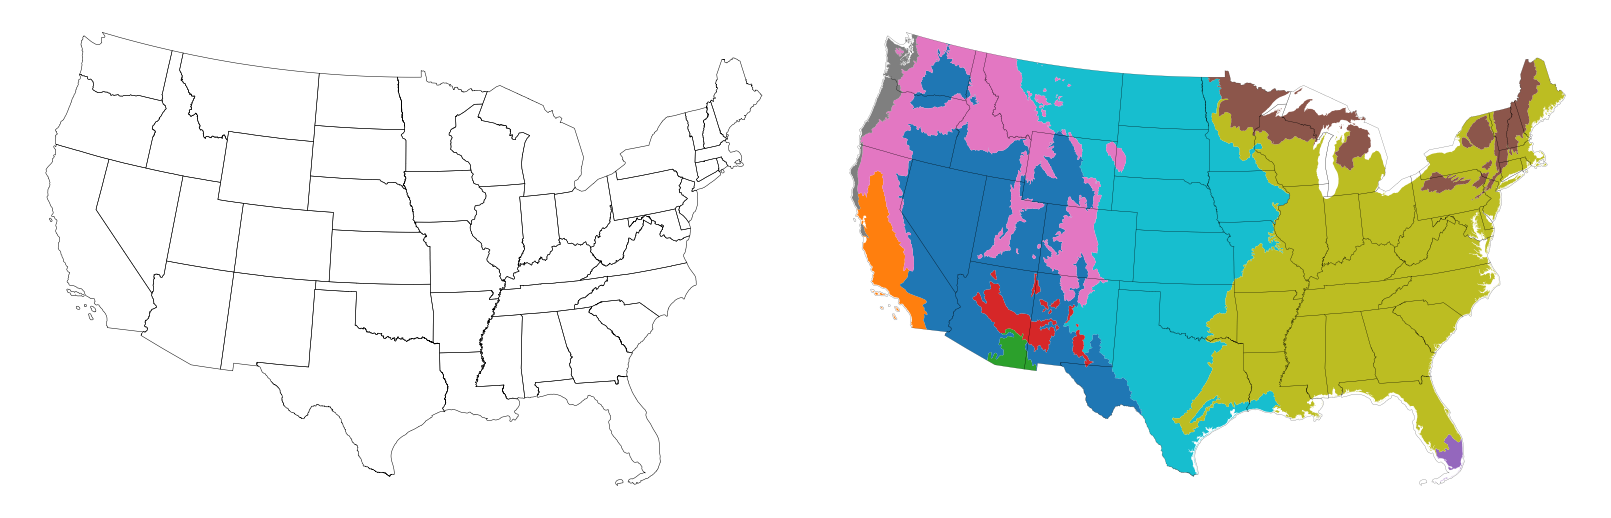

In [ ]:
states = gpd.read_file(ROOT / sampling_cfg["conus"]["path"])
states = states[states["REGION"].astype(str).isin(["1", "2", "3", "4"]) & ~states["STUSPS"].isin(["AK", "HI"])].to_crs(
    CRS
)
conus = states.geometry.union_all()

ecoregions = gpd.read_file(ROOT / sampling_cfg["ecoregions"]["path"])
ecoregions = ecoregions[ecoregions["NA_L1CODE"] != "0"].to_crs(CRS)
ecoregions = ecoregions.dissolve(by=["NA_L1CODE", "NA_L1NAME"], as_index=False)
ecoregions = gpd.clip(ecoregions, gpd.GeoSeries([conus], crs=CRS))
ecoregions = ecoregions[~ecoregions.is_empty].copy()

urban = gpd.read_file(ROOT / sampling_cfg["census_urban"]["path"]).to_crs(CRS)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)
states.boundary.plot(ax=axes[0], linewidth=0.35, color="black")
ecoregions.plot(column="NA_L1CODE", ax=axes[1], categorical=True, cmap="tab10")
states.boundary.plot(ax=axes[1], linewidth=0.2, color="black", alpha=0.6)
for ax in axes:
    ax.set_axis_off()
fig.savefig(figure_dir / "sampling_frame_boundaries.png", dpi=180)
plt.show()

In [3]:
minx, miny, maxx, maxy = conus.bounds
xs = np.arange(math.floor(minx / CELL_SIZE_M) * CELL_SIZE_M, math.ceil(maxx / CELL_SIZE_M) * CELL_SIZE_M, CELL_SIZE_M)
ys = np.arange(math.floor(miny / CELL_SIZE_M) * CELL_SIZE_M, math.ceil(maxy / CELL_SIZE_M) * CELL_SIZE_M, CELL_SIZE_M)

cell_rows = [
    {
        "cell_id": f"{ix:03d}_{iy:03d}",
        "grid_x": ix,
        "grid_y": iy,
        "geometry": box(x, y, x + CELL_SIZE_M, y + CELL_SIZE_M),
    }
    for ix, x in enumerate(xs)
    for iy, y in enumerate(ys)
]
cells = gpd.GeoDataFrame(cell_rows, crs=CRS)
centres = cells.copy()
centres.geometry = cells.geometry.centroid
centres = centres[centres.within(conus)].copy()

urban_join = gpd.sjoin(centres, urban[["geometry"]], how="left", predicate="within")
rural_index = urban_join.loc[urban_join["index_right"].isna()].index.unique()
centres = centres.loc[rural_index]
centres = gpd.sjoin(
    centres,
    ecoregions[["NA_L1CODE", "NA_L1NAME", "geometry"]],
    how="inner",
    predicate="within",
).drop(columns="index_right")
centres = gpd.sjoin(centres, states[["STUSPS", "geometry"]], how="inner", predicate="within")
centres = centres[~centres.index.duplicated(keep="first")].copy()

candidate_counts = centres.groupby("NA_L1CODE").size().sort_index(key=lambda index: index.astype(int))
extra_total = TOTAL_BOXES - MIN_BOXES_PER_STRATUM * len(candidate_counts)
raw_extra = extra_total * candidate_counts / candidate_counts.sum()
quotas = MIN_BOXES_PER_STRATUM + np.floor(raw_extra).astype(int)
remainder = TOTAL_BOXES - int(quotas.sum())
for code in (raw_extra - np.floor(raw_extra)).sort_values(ascending=False, kind="stable").index[:remainder]:
    quotas.loc[code] += 1

rng = np.random.default_rng(SEED)
selected_indices = []
selection_rank = {}
for code, quota in quotas.items():
    candidates = centres[centres["NA_L1CODE"] == code].copy()
    candidates["serpentine_y"] = np.where(candidates["grid_x"] % 2 == 0, candidates["grid_y"], -candidates["grid_y"])
    candidates = candidates.sort_values(["STUSPS", "grid_x", "serpentine_y"])
    interval = len(candidates) / quota
    positions = np.floor(rng.uniform(0, interval) + np.arange(quota) * interval).astype(int)
    chosen = candidates.index.to_numpy()[positions]
    selected_indices.extend(chosen)
    selection_rank.update({idx: rank for rank, idx in enumerate(chosen, start=1)})

selected = cells.loc[selected_indices, ["cell_id", "grid_x", "grid_y", "geometry"]].copy()
selected["ecoregion_code"] = centres.loc[selected.index, "NA_L1CODE"]
selected["ecoregion_name"] = centres.loc[selected.index, "NA_L1NAME"]
selected["state"] = centres.loc[selected.index, "STUSPS"]
selected["rank_in_ecoregion"] = selected.index.map(selection_rank)
selected["candidate_cells_in_ecoregion"] = selected["ecoregion_code"].map(candidate_counts)
selected["selected_cells_in_ecoregion"] = selected["ecoregion_code"].map(quotas)
selected["cell_selection_probability"] = (
    selected["selected_cells_in_ecoregion"] / selected["candidate_cells_in_ecoregion"]
)
selected = selected.sort_values(
    ["ecoregion_code", "rank_in_ecoregion"],
    key=lambda column: column.astype(int) if column.name == "ecoregion_code" else column,
)

assert len(selected) == TOTAL_BOXES
assert selected.groupby("ecoregion_code").size().eq(quotas).all()

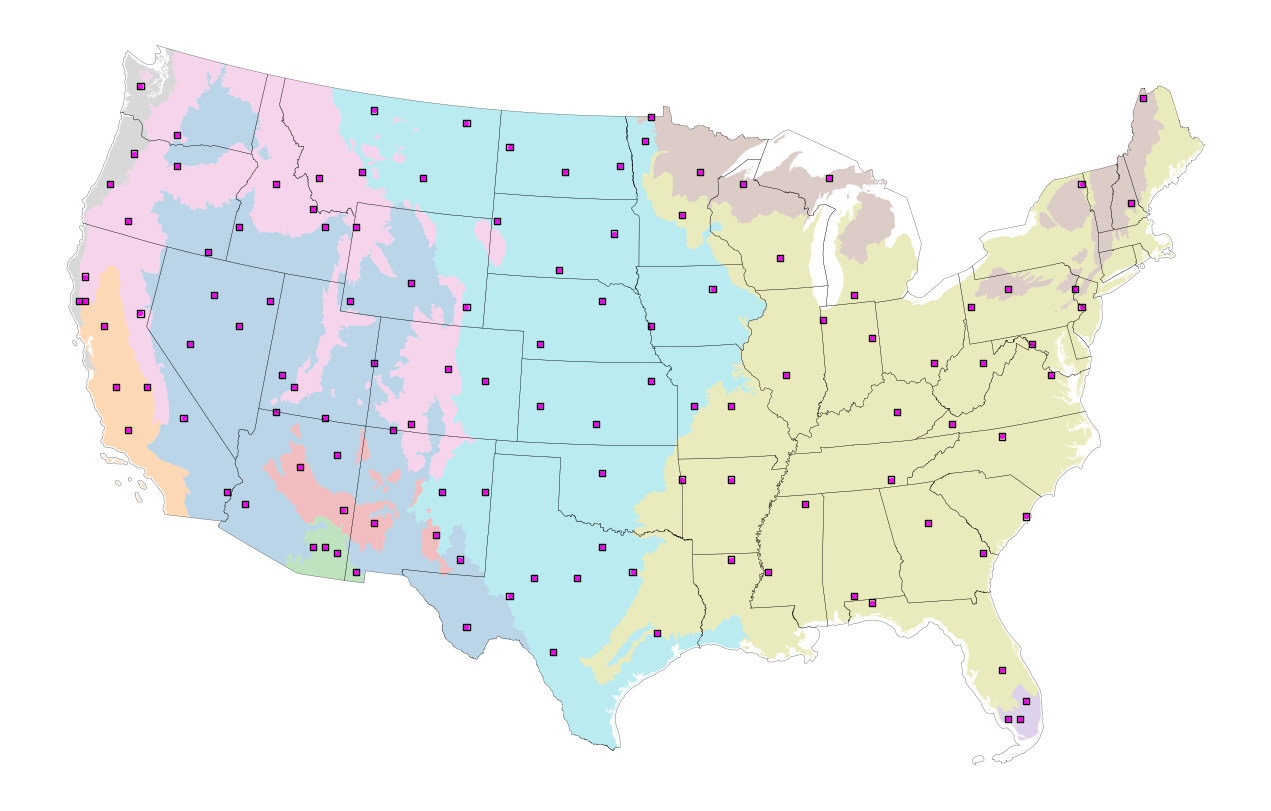

In [4]:
fig, ax = plt.subplots(figsize=(13, 8), constrained_layout=True)
ecoregions.plot(column="NA_L1CODE", ax=ax, categorical=True, cmap="tab10", alpha=0.3)
states.boundary.plot(ax=ax, linewidth=0.25, color="black", alpha=0.7)
selected.boundary.plot(ax=ax, linewidth=1.0, color="black")
selected.centroid.plot(ax=ax, markersize=8, color="magenta")
ax.set_axis_off()
fig.savefig(figure_dir / "sampling_frame_selected.png", dpi=180)
plt.show()

In [5]:
selected_wgs84 = selected.to_crs("EPSG:4326")
bbox_records = []
for row in selected_wgs84.itertuples():
    xmin, ymin, xmax, ymax = row.geometry.bounds
    bbox_records.append(
        {
            "name": f"eco_{row.ecoregion_code}_box_{row.rank_in_ecoregion:02d}",
            "grid_x": int(row.grid_x),
            "grid_y": int(row.grid_y),
            "ecoregion_code": str(row.ecoregion_code),
            "ecoregion_name": row.ecoregion_name,
            "state": row.state,
            "candidate_cells_in_ecoregion": int(row.candidate_cells_in_ecoregion),
            "selected_cells_in_ecoregion": int(row.selected_cells_in_ecoregion),
            "cell_selection_probability": round(float(row.cell_selection_probability), 10),
            "xmin": round(float(xmin), 6),
            "ymin": round(float(ymin), 6),
            "xmax": round(float(xmax), 6),
            "ymax": round(float(ymax), 6),
        }
    )

overture_path = ROOT / "configs/overture.yaml"
overture_cfg = yaml.safe_load(overture_path.read_text())
overture_cfg["bboxes"] = bbox_records
overture_path.write_text(yaml.safe_dump(overture_cfg, sort_keys=False, width=120))
selected.to_parquet(audit_dir / "selected_bboxes.parquet", index=False)

print(f"{len(bbox_records)} boxes, {selected.state.nunique()} states")

120 boxes, 43 states
